# Notebook C: external check on PAMAP2

Reviewer 1 asked whether the MHEALTH findings hold on another data set. PAMAP2 (Reiss and Stricker, 2012, UCI, CC BY 4.0)
is the closest public match: inertial units on the **dominant wrist, the chest and the dominant ankle**, plus a **heart-rate
strap on the chest**, so the "chest device" again means a chest motion sensor plus a heart signal.

This notebook repeats, with the same feature recipe and the same model settings as Notebook B:
1. retraining with one position removed or kept alone, leave-one-person-out, LightGBM / Extra Trees / XGBoost, 3 seeds;
2. TOST equivalence tests (margin ±0.03) for the cost of dropping each position;
3. ROAR (masked vs retrained, top 10 features) for five explanation methods;
4. a mutual-information baseline for choosing the position to drop.

Differences from MHEALTH, stated up front: 8 people (subject 109 performed almost none of the protocol), 12 protocol
activities but not every person did every activity, so macro-F1 is averaged over the activities present for the held-out
person; 100 Hz signals, 2 s windows with a 1 s step; features are mean and SD of the ±16 g accelerometer, the gyroscope and
the acceleration magnitude per position, and mean and SD of heart rate (44 features).

In [1]:
# Step C1: download PAMAP2 from UCI (about 690 MB) and cut 2 s windows; skipped when the processed file already exists
import os, glob, io, zipfile, urllib.request, json, time, itertools
import numpy as np, pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
os.makedirs('data/raw', exist_ok=True); os.makedirs('data/processed', exist_ok=True); os.makedirs('report', exist_ok=True)
PARQUET = 'data/processed/pamap2.parquet'
RAW = 'data/raw/PAMAP2_Dataset/Protocol'
URL = 'https://archive.ics.uci.edu/static/public/231/pamap2+physical+activity+monitoring.zip'
ACT = {1: 'lying', 2: 'sitting', 3: 'standing', 4: 'walking', 5: 'running', 6: 'cycling', 7: 'nordic walking',
       12: 'ascending stairs', 13: 'descending stairs', 16: 'vacuum cleaning', 17: 'ironing', 24: 'rope jumping'}
IMU = {'wrist': 3, 'chest': 20, 'ankle': 37}            # first column of each IMU block (hand IMU = dominant wrist)
WIN, STEP = 200, 100                                     # 100 Hz: 2 s windows, 1 s step

def build(raw_dir):
    cols, names = [0, 1, 2], ['t', 'act', 'hr']
    for pos, b in IMU.items():
        cols += [b + 1, b + 2, b + 3, b + 7, b + 8, b + 9]       # +-16 g accelerometer, gyroscope
        names += [f'{pos}_acc_x', f'{pos}_acc_y', f'{pos}_acc_z', f'{pos}_gyro_x', f'{pos}_gyro_y', f'{pos}_gyro_z']
    rows = []
    for f in sorted(glob.glob(os.path.join(raw_dir, 'subject10[1-8].dat'))):
        sid = int(os.path.basename(f)[7:10])
        d = pd.read_csv(f, sep=' ', header=None, usecols=cols, engine='c')[cols]; d.columns = names
        d['hr'] = d['hr'].ffill().bfill()                         # heart rate arrives at about 9 Hz
        for pos in IMU: d[f'{pos}_accmag'] = np.sqrt(d[f'{pos}_acc_x'] ** 2 + d[f'{pos}_acc_y'] ** 2 + d[f'{pos}_acc_z'] ** 2)
        ch = [c for c in d.columns if c not in ('t', 'act')]
        for _, g in d.groupby((d.act != d.act.shift()).cumsum(), sort=False):     # one block per continuous activity
            a = int(g.act.iloc[0])
            if a not in ACT or len(g) < WIN: continue
            V = sliding_window_view(g[ch].to_numpy(float), WIN, axis=0)[::STEP]
            V = V[(np.isnan(V).mean(axis=2) <= 0.2).all(axis=1)]                    # drop windows with >20 % lost packets
            if not len(V): continue
            F = np.empty((len(V), 2 * len(ch))); F[:, 0::2] = np.nanmean(V, axis=2); F[:, 1::2] = np.nanstd(V, axis=2, ddof=1)
            r = pd.DataFrame(F, columns=[f'{c}_{s}' for c in ch for s in ('mean', 'std')])
            r.insert(0, 'activity', ACT[a]); r.insert(0, 'subject', sid); rows.append(r)
    out = pd.concat(rows, ignore_index=True).rename(columns={'hr_mean': 'heart_rate_mean', 'hr_std': 'heart_rate_std'})
    return out.dropna().reset_index(drop=True)

if not os.path.exists(PARQUET):
    if not os.path.isdir(RAW):
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))
        zipfile.ZipFile(io.BytesIO(z.read('PAMAP2_Dataset.zip'))).extractall('data/raw')
    build(RAW).to_parquet(PARQUET, index=False)
feat = pd.read_parquet(PARQUET)
json.dump({'rows': len(feat), 'columns': list(feat.columns)}, open('data/processed/pamap2_manifest.json', 'w'), indent=1)
print(feat.shape); print(pd.crosstab(feat.activity, feat.subject))

(19178, 46)
subject            101  102  103  104  105  106  107  108
activity                                                 
ascending stairs   156  171  101  164  140  130  174  114
cycling            234  250    0  225  244  203  225  253
descending stairs  146  149  148  140  124  109  113   94
ironing            234  287  278  248  329  375  293  328
lying              270  231  219  229  235  232  255  240
nordic walking     201  291    0  274  261  265  286  287
rope jumping       128  131    0    0   76    1    0   87
running            211   91    0    0  245  227   35  164
sitting            233  222  286  253  267  225  120  228
standing           216  254  204  246  220  241  256  250
vacuum cleaning    228  205  202  199  243  209  214  241
walking            219  322  289  311  318  256  336  314


In [2]:
# Step C2: same models, explanation methods and tests as Notebook B
import shap
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import Ridge
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from scipy import stats
X_cols = [c for c in feat.columns if c not in ('subject', 'activity')]
people = sorted(feat.subject.unique())
classes = sorted(feat.activity.unique()); code = {c: i for i, c in enumerate(classes)}
X_all, y_all, subj = feat[X_cols], feat.activity.map(code), feat.subject.to_numpy()
GROUP = pd.Series(X_cols, index=X_cols).str.split('_').str[0].replace({'heart': 'heart signal'})
dev = GROUP.replace({'heart signal': 'chest'})          # the heart-rate strap sits on the chest
MODELS3 = {
    'LightGBM':    lambda s: LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                            subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1),
    'Extra Trees': lambda s: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'XGBoost':     lambda s: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                                           colsample_bytree=0.8, tree_method='hist', random_state=s)}
def fit_best(X, y, seed=0, name='LightGBM'): return MODELS3[name](seed).fit(X, y)
def f1(m, X, y): return f1_score(y, m.predict(X), labels=np.unique(y), average='macro')   # activities this person did
MARGIN = 0.03
def compare(d):
    d = np.asarray(d, float); n = len(d); mu = d.mean(); se = d.std(ddof=1) / np.sqrt(n); tq = stats.t.ppf(0.975, n - 1)
    p_tost = max(1 - stats.t.cdf((mu + MARGIN) / se, n - 1), stats.t.cdf((mu - MARGIN) / se, n - 1))
    p_w = stats.wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    lo, hi = mu - tq * se, mu + tq * se
    verdict = 'equivalent (±0.03)' if p_tost < 0.05 else ('different' if p_w < 0.05 and (lo > 0 or hi < 0) else 'unresolved')
    return dict(mean_diff=mu, ci_low=lo, ci_high=hi, wilcoxon_p=p_w, tost_p=p_tost, verdict=verdict)
def pool(sv):
    if isinstance(sv, list): sv = np.stack(sv, axis=-1)
    sv = np.abs(np.asarray(sv)); return sv.mean(axis=0) if sv.ndim == 2 else sv.mean(axis=(0, 2))
def r_tree_shap(m, Xtr, X, y, n=200): return pool(shap.TreeExplainer(m).shap_values(X.sample(min(n, len(X)), random_state=0)))
def r_kernel_shap(m, Xtr, X, y, n=50):
    np.random.seed(0); f = lambda Z: m.predict_proba(pd.DataFrame(Z, columns=X.columns))
    return pool(shap.KernelExplainer(f, shap.kmeans(Xtr[X.columns], 20)).shap_values(X.sample(n, random_state=0), nsamples=300, silent=True))
def r_lime(m, Xtr, X, y, n=50, n_pert=500):
    f = lambda Z: m.predict_proba(pd.DataFrame(Z, columns=X.columns))
    rs = np.random.RandomState(0); sd = Xtr[X.columns].std().to_numpy() + 1e-9; w = np.zeros(X.shape[1])
    for x in X.sample(n, random_state=0).to_numpy():
        Z = x + rs.randn(n_pert, len(x)) * sd; p = f(Z)[:, f(x[None]).argmax()]
        d = np.sqrt((((Z - x) / sd) ** 2).sum(1)); k = np.exp(-d ** 2 / (0.75 * np.sqrt(len(x))) ** 2)
        w += np.abs(Ridge(alpha=1.0).fit((Z - x) / sd, p, sample_weight=k).coef_)
    return w / n
def r_perm(m, Xtr, X, y, n=3000):
    Xv = X.sample(min(n, len(X)), random_state=0)
    return permutation_importance(m, Xv, y.loc[Xv.index], n_repeats=3, scoring='f1_macro', random_state=0).importances_mean
def r_gain(m, Xtr, X, y): return m.booster_.feature_importance('gain') if hasattr(m, 'booster_') else m.feature_importances_
METHODS = {'TreeSHAP': r_tree_shap, 'KernelSHAP': r_kernel_shap, 'LIME': r_lime, 'Permutation': r_perm, 'Gain': r_gain}
def explain_all(m, Xtr, X, y):
    return {k: pd.Series(f(m, Xtr, X, y), index=X.columns).sort_values(ascending=False) for k, f in METHODS.items()}
print(len(people), 'people,', len(classes), 'activities,', len(X_cols), 'features')
print(GROUP.value_counts())

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


8 people, 12 activities, 44 features
wrist           14
chest           14
ankle           14
heart signal     2
Name: count, dtype: int64


In [3]:
# Step C3: retraining with positions removed or kept alone (LOSO over 8 people, 3 models, 3 seeds); resumes from its CSV
SEEDS = [0, 1, 2]
pick = lambda keep: list(GROUP.index[keep])
SETS = {'all': X_cols, 'drop chest device': pick(dev != 'chest'), 'drop wrist': pick(GROUP != 'wrist'), 'drop ankle': pick(GROUP != 'ankle'),
        'only ankle': pick(GROUP == 'ankle'), 'only chest device (IMU + heart rate)': pick(dev == 'chest'), 'only wrist': pick(GROUP == 'wrist'),
        'only chest IMU': pick(GROUP == 'chest'), 'only heart signal': pick(GROUP == 'heart signal')}
path = 'report/pamap2_positions_folds.csv'
pos = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=['model', 'setting', 'held_out', 'seed', 'macroF1'])
for mname in MODELS3:
    for sname, c in SETS.items():
        if ((pos.model == mname) & (pos.setting == sname)).any(): continue
        t0 = time.perf_counter(); new = []
        for s_out in people:
            tr, te = subj != s_out, subj == s_out
            for s in SEEDS: new.append([mname, sname, s_out, s, f1(fit_best(X_all.loc[tr, c], y_all[tr], s, mname), X_all.loc[te, c], y_all[te])])
        pos = pd.concat([pos, pd.DataFrame(new, columns=pos.columns)], ignore_index=True); pos.to_csv(path, index=False)
        print(f'{mname:12s} {sname:38s} {pd.DataFrame(new)[4].mean():.3f} ({time.perf_counter() - t0:.0f} s)', flush=True)
pp = pos.groupby(['model', 'setting', 'held_out'], sort=False).macroF1.mean().reset_index()
pos_tab = pp.groupby(['model', 'setting'], sort=False).macroF1.agg(['mean', 'std', 'min']).reset_index()
pos_tab['loss_vs_all'] = pos_tab['mean'] - pos_tab.model.map(pos_tab[pos_tab.setting == 'all'].set_index('model')['mean'])
pos_tab.to_csv('report/pamap2_positions.csv', index=False)
print(pos_tab.pivot(index='setting', columns='model', values='mean').loc[list(SETS)].round(3))
print(pos_tab.pivot(index='setting', columns='model', values='min').loc[list(SETS)].round(3).add_suffix(' (worst)'))

XGBoost      drop chest device                      0.819 (215 s)


XGBoost      drop wrist                             0.765 (224 s)


XGBoost      drop ankle                             0.801 (215 s)


XGBoost      only ankle                             0.654 (132 s)


XGBoost      only chest device (IMU + heart rate)   0.736 (139 s)


XGBoost      only wrist                             0.706 (146 s)


XGBoost      only chest IMU                         0.734 (140 s)


XGBoost      only heart signal                      0.301 (67 s)


model                                 Extra Trees  LightGBM  XGBoost
setting                                                             
all                                         0.880     0.853    0.845
drop chest device                           0.852     0.806    0.819
drop wrist                                  0.797     0.760    0.765
drop ankle                                  0.834     0.797    0.801
only ankle                                  0.673     0.642    0.654
only chest device (IMU + heart rate)        0.726     0.730    0.736
only wrist                                  0.716     0.704    0.706
only chest IMU                              0.720     0.728    0.734
only heart signal                           0.297     0.286    0.301
model                                 Extra Trees (worst)  LightGBM (worst)  \
setting                                                                       
all                                                 0.815             0.779   
drop

In [4]:
# Step C4: is the cost of each setting different from zero, or equivalent within 0.03? (paired over the 8 people)
W = pp.pivot_table(index=['model', 'held_out'], columns='setting', values='macroF1')
pos_tests = pd.DataFrame([{'model': mname, 'comparison': f'all - {s}', **compare(W.loc[mname]['all'] - W.loc[mname][s])}
                          for mname in MODELS3 for s in SETS if s != 'all'])
pos_tests.to_csv('report/pamap2_positions_tests.csv', index=False); print(pos_tests.round(4).to_string(index=False))

      model                                 comparison  mean_diff  ci_low  ci_high  wilcoxon_p  tost_p    verdict
   LightGBM                    all - drop chest device     0.0472 -0.0364   0.1309      0.3125  0.6793 unresolved
   LightGBM                           all - drop wrist     0.0933  0.0480   0.1387      0.0078  0.9935  different
   LightGBM                           all - drop ankle     0.0560 -0.0163   0.1282      0.0234  0.7883 unresolved
   LightGBM                           all - only ankle     0.2114  0.1167   0.3061      0.0078  0.9986  different
   LightGBM all - only chest device (IMU + heart rate)     0.1234  0.0178   0.2289      0.0078  0.9626  different
   LightGBM                           all - only wrist     0.1487  0.0637   0.2338      0.0078  0.9935  different
   LightGBM                       all - only chest IMU     0.1251  0.0241   0.2260      0.0078  0.9694  different
   LightGBM                    all - only heart signal     0.5675  0.5154   0.6197      

In [5]:
# Step C5: ROAR on a fixed person split (people 106-108 held out), top 10 features, LightGBM and Extra Trees
TEST_P = people[-3:]
te_mask = feat.subject.isin(TEST_P).to_numpy(); Xa, ya, Xb, yb = X_all[~te_mask], y_all[~te_mask], X_all[te_mask], y_all[te_mask]
assert set(ya) == set(range(len(classes))), 'every activity is in the training people'
path = 'report/pamap2_roar.csv'
roar = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=['model', 'method', 'k', 'base', 'masked', 'retrained', 'retrained_sd'])
ranks = {}
for mname in ['LightGBM', 'Extra Trees']:
    m = fit_best(Xa, ya, 0, mname); R = explain_all(m, Xa, Xb, yb)
    if mname == 'LightGBM': ranks = R
    if (roar.model == mname).any(): continue
    t0 = time.perf_counter(); base = np.mean([f1(fit_best(Xa, ya, s, mname), Xb, yb) for s in SEEDS])
    R['Random'] = pd.Series(np.random.RandomState(0).rand(len(X_cols)), index=X_cols).sort_values(ascending=False)
    new = []
    for meth, r in R.items():
        top = list(r.index[:10]); keep = [c for c in X_cols if c not in top]
        Xp = Xb.copy(); Xp[top] = Xa[top].mean().values
        rt = [f1(fit_best(Xa[keep], ya, s, mname), Xb[keep], yb) for s in SEEDS]
        new.append([mname, meth, 10, base, f1(m, Xp, yb), np.mean(rt), np.std(rt)])
    roar = pd.concat([roar, pd.DataFrame(new, columns=roar.columns)], ignore_index=True); roar.to_csv(path, index=False)
    print(f'{mname} base {base:.3f} ({time.perf_counter() - t0:.0f} s)', flush=True)
print(roar.round(3).to_string(index=False))
share = pd.DataFrame({k: (r.clip(lower=0) / r.clip(lower=0).sum()).groupby(GROUP).sum() for k, r in ranks.items()})
share.to_csv('report/pamap2_group_share.csv'); print(share.round(3))

LightGBM base 0.834 (179 s)


Extra Trees base 0.882 (31 s)


      model      method  k      base    masked retrained retrained_sd
   LightGBM    TreeSHAP 10   0.83371  0.481816  0.841666     0.000437
   LightGBM  KernelSHAP 10   0.83371  0.456617  0.787684     0.002079
   LightGBM        LIME 10   0.83371  0.449075  0.781446     0.004946
   LightGBM Permutation 10   0.83371   0.55093  0.737452     0.011546
   LightGBM        Gain 10   0.83371  0.471027  0.757436     0.006299
   LightGBM      Random 10   0.83371  0.759823  0.828098     0.002211
Extra Trees    TreeSHAP 10  0.881783  0.427675  0.831583     0.007792
Extra Trees  KernelSHAP 10  0.881783  0.394183  0.839548     0.013176
Extra Trees        LIME 10  0.881783  0.351154    0.8067     0.002783
Extra Trees Permutation 10  0.881783  0.593808  0.785965     0.004379
Extra Trees        Gain 10  0.881783   0.51762  0.831034     0.001421
Extra Trees      Random 10  0.881783  0.822973  0.871659     0.005571
              TreeSHAP  KernelSHAP   LIME  Permutation   Gain  Random
ankle            0.2

In [6]:
# Step C6: model-free baseline for choosing the position to drop: mutual information, compared with attribution and retrain cost
from sklearn.feature_selection import mutual_info_classif
sub = feat[~te_mask].sample(10000, random_state=0)
mi = pd.Series(mutual_info_classif(sub[X_cols], sub.activity.map(code), random_state=0), index=X_cols)
cost = pos_tab[pos_tab.setting.str.startswith('drop')].assign(device=lambda d: d.setting.str.replace('drop ', '').str.replace(' device', ''))
cost = cost.pivot(index='device', columns='model', values='loss_vs_all').mul(-1).add_prefix('retrain cost ')
base_sel = pd.DataFrame({'features': dev.value_counts(), 'MI sum': mi.groupby(dev).sum(), 'MI per feature': mi.groupby(dev).mean(),
                         'TreeSHAP share': (ranks['TreeSHAP'] / ranks['TreeSHAP'].sum()).groupby(dev).sum(),
                         'TreeSHAP per feature': (ranks['TreeSHAP'] / ranks['TreeSHAP'].sum()).groupby(dev).mean()}).join(cost)
base_sel.to_csv('report/pamap2_selection_baselines.csv'); print(base_sel.round(3))
for c in base_sel.columns[1:]: print(f'{c:28s} would drop first: {base_sel[c].idxmin()}')

       features  MI sum  MI per feature  TreeSHAP share  TreeSHAP per feature  \
ankle        14  12.382           0.884           0.296                 0.021   
chest        16  11.536           0.721           0.440                 0.028   
wrist        14   8.922           0.637           0.264                 0.019   

       retrain cost Extra Trees  retrain cost LightGBM  retrain cost XGBoost  
ankle                     0.046                  0.056                 0.043  
chest                     0.028                  0.047                 0.026  
wrist                     0.083                  0.093                 0.080  
MI sum                       would drop first: wrist
MI per feature               would drop first: wrist
TreeSHAP share               would drop first: wrist
TreeSHAP per feature         would drop first: wrist
retrain cost Extra Trees     would drop first: chest
retrain cost LightGBM        would drop first: chest
retrain cost XGBoost         would drop f

data set       model  chest device  wrist  ankle cheapest to drop
 MHEALTH    LightGBM         0.042  0.070  0.084     chest device
 MHEALTH Extra Trees         0.026  0.072  0.079     chest device
 MHEALTH     XGBoost         0.058  0.065  0.101     chest device
  PAMAP2    LightGBM         0.047  0.093  0.056     chest device
  PAMAP2 Extra Trees         0.028  0.083  0.046     chest device
  PAMAP2     XGBoost         0.026  0.080  0.043     chest device


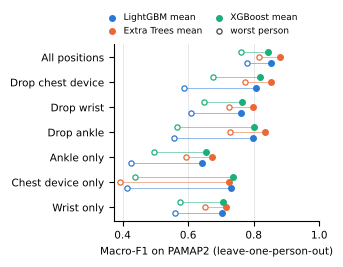

In [7]:
# Step C7: MHEALTH and PAMAP2 side by side: cost of dropping each device, per model
import matplotlib.pyplot as plt
mh = pd.read_csv('report/table_rq3_positions.csv')
rows = []
for name, t in [('MHEALTH', mh), ('PAMAP2', pos_tab)]:
    for mname in MODELS3:
        s = t[(t.model == mname) & t.setting.str.startswith('drop')].set_index('setting')['loss_vs_all'].mul(-1)
        rows.append({'data set': name, 'model': mname, **{k.replace('drop ', ''): v for k, v in s.items()}, 'cheapest to drop': s.idxmin().replace('drop ', '')})
ext = pd.DataFrame(rows); ext.to_csv('report/table_external_check.csv', index=False); print(ext.round(3).to_string(index=False))

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 7.5, 'axes.spines.top': False, 'axes.spines.right': False})
COL = {'LightGBM': '#2a78d6', 'Extra Trees': '#eb6834', 'XGBoost': '#1baf7a'}
LABEL = {'all': 'All positions', 'drop chest device': 'Drop chest device', 'drop wrist': 'Drop wrist', 'drop ankle': 'Drop ankle',
         'only ankle': 'Ankle only', 'only chest device (IMU + heart rate)': 'Chest device only', 'only wrist': 'Wrist only'}
order = list(LABEL)[::-1]; yy = np.arange(len(order))
fig, ax = plt.subplots(figsize=(3.4, 2.7))
for j, (mname, col) in enumerate(COL.items()):
    s = pos_tab[pos_tab.model == mname].set_index('setting').loc[order]; off = (j - 1) * 0.22
    ax.scatter(s['mean'], yy + off, color=col, s=16, zorder=3, label=f'{mname} mean')
    ax.scatter(s['min'], yy + off, facecolors='white', edgecolors=col, s=14, linewidths=0.9, zorder=3)
    ax.hlines(yy + off, s['min'], s['mean'], color=col, lw=0.6, alpha=0.6)
ax.scatter([], [], facecolors='white', edgecolors='#555555', s=14, label='worst person')
ax.set_yticks(yy, [LABEL[o] for o in order]); ax.set_xlabel('Macro-F1 on PAMAP2 (leave-one-person-out)')
ax.set_xlim(min(0.45, float(pos_tab[pos_tab.setting.isin(order)]['min'].min()) - 0.02), 1.0)
ax.grid(axis='x', color='#dddddd', lw=0.5); ax.set_axisbelow(True)
ax.legend(loc='lower center', bbox_to_anchor=(0.42, 1.0), ncol=2, frameon=False, fontsize=6.5, handletextpad=0.3, columnspacing=0.8)
fig.tight_layout(); fig.savefig('report/fig_pamap2_positions_3models.png', dpi=300, bbox_inches='tight'); plt.show()
plt.rcParams.update(plt.rcParamsDefault)

In [8]:
# Step C8: checks
assert len(people) == 8 and len(X_cols) == 44
assert len(pos) == len(MODELS3) * len(SETS) * len(people) * len(SEEDS)
assert set(roar.model) == {'LightGBM', 'Extra Trees'} and len(roar) == 2 * 6
for f in ['pamap2_positions.csv', 'pamap2_positions_tests.csv', 'pamap2_roar.csv', 'pamap2_group_share.csv',
          'pamap2_selection_baselines.csv', 'table_external_check.csv', 'fig_pamap2_positions_3models.png']:
    assert os.path.exists('report/' + f), f
print('all checks passed')

all checks passed
